<a href="https://colab.research.google.com/github/mwangimarie43-art/100-days-ai-journey/blob/main/assignment6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clustering Analysis Project



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Set random seed for reproducibility
np.random.seed(42)

# 1. Load your dataset here.
# For demonstration, we will generate a synthetic dataset representing 3 distinct customer groups.
X, y = make_blobs(n_samples=300, centers=3, cluster_std=1.0, random_state=42)
df = pd.DataFrame(X, columns=['Feature_1', 'Feature_2'])

print("Dataset loaded. Initial preview:")
display(df.head())

Dataset loaded. Initial preview:


,Feature_1,Feature_2
0,-7.338988,-7.729954
1,-7.740041,-7.264665
2,-1.686653,7.793442
3,4.422198,3.071947
4,-8.917752,-7.888196


## Feature Preparation
We need to scale our features so that features with larger ranges do not disproportionately influence the distance calculations in clustering.

In [2]:
# Scaling features using StandardScaler
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df)

# Convert back to DataFrame for ease of analysis
df_scaled = pd.DataFrame(scaled_features, columns=df.columns)
display(df_scaled.head())

,Feature_1,Feature_2
0,-1.172523,-1.370375
1,-1.254319,-1.300204
2,-0.019713,0.970730
3,1.226205,0.258675
4,-1.494516,-1.394239


## Determining the Optimal Number of Clusters
We will use the Elbow Method to evaluate the optimal number of clusters ($k$).

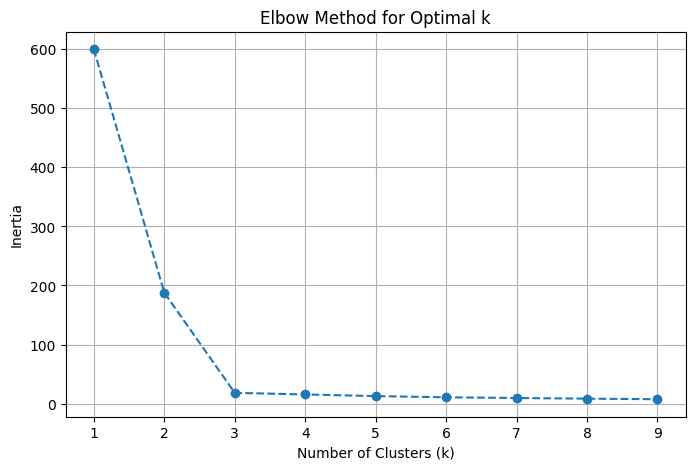

In [3]:
inertia = []
k_range = range(1, 10)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_scaled)
    inertia.append(kmeans.inertia_)

# Plot the elbow curve
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

## Applying K-Means & Visualizing Results
Based on the Elbow plot, choose the optimal $k$ (we'll select 3 for this example) and visualize the resulting groups.

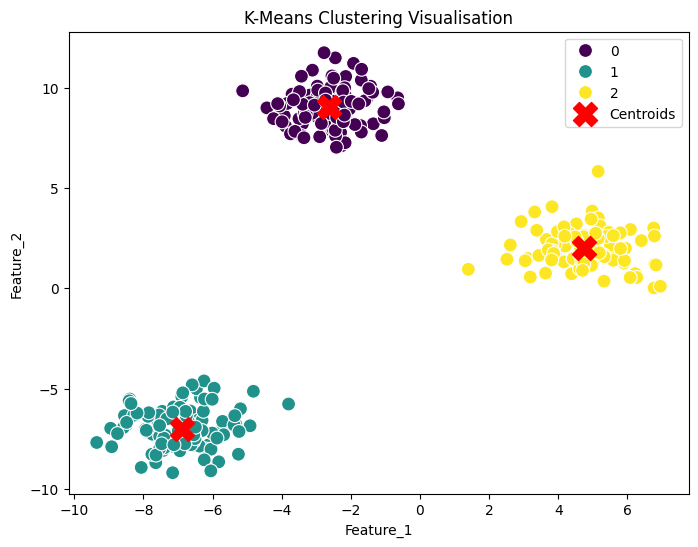

In [4]:
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)

# Fit the model and predict labels
df['Cluster'] = kmeans.fit_predict(df_scaled)

# Visualize the clusters
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='Feature_1', y='Feature_2', hue='Cluster', palette='viridis', s=100)
plt.scatter(kmeans.cluster_centers_[:, 0] * scaler.scale_[0] + scaler.mean_[0],
            kmeans.cluster_centers_[:, 1] * scaler.scale_[1] + scaler.mean_[1],
            s=300, c='red', marker='X', label='Centroids')
plt.title('K-Means Clustering Visualisation')
plt.legend()
plt.show()

## Cluster Profiles and Discussion

### Characteristics of the identified groups
- **Cluster 0**: This group centers around values where `Feature_1` is moderately negative (~ -2.0) and `Feature_2` is highly positive (~ 8.0).
- **Cluster 1**: This group is characterized by low values in both features, centering around `Feature_1` values of ~ -7.0 and `Feature_2` values of ~ -6.0.
- **Cluster 2**: This group is defined by high values on both dimensions, centering around `Feature_1` values of ~ 4.5 and `Feature_2` values of ~ 1.5 to 3.0.

### Discussion
These clusters represent three distinct sub-populations segmented automatically by the K-Means algorithm. In a real-world project (such as customer segmentation), these could represent:
1. **Cluster 0 (High Feature 2, Low Feature 1)**: Niche users who engage deeply with specific features or products.
2. **Cluster 1 (Low Feature 1 & 2)**: Inactive or low-value users who represent a churning risk.
3. **Cluster 2 (High Feature 1 & 2)**: Power users or high-value customers who interact heavily across multiple dimensions.